# PricePilot — Exploratory Data Analysis

We inspect the raw Bengaluru housing dataset before making preprocessing decisions. Do not overwrite or modify the source CSV.

In [7]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Bengaluru_House_Data.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")
df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")


Dataset loaded successfully
Rows: 13,320 | Columns: 9


## 1. Dataset structure
Check column names, data types, non-null counts, and memory usage.

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [9]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Dataset shape: (13320, 9)

Column names:
['area_type', 'availability', 'location', 'size', 'society', 'total_sqft', 'bath', 'balcony', 'price']

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
area_type,13320,4,Super built-up Area,8790,NaN,NaN,NaN,NaN,NaN,NaN,NaN
availability,13320,81,Ready To Move,10581,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,13319,1305,Whitefield,540,NaN,NaN,NaN,NaN,NaN,NaN,NaN
size,13304,31,2 BHK,5199,NaN,NaN,NaN,NaN,NaN,NaN,NaN
society,7818,2688,GrrvaGr,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_sqft,13320,2117,1200,843,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bath,13247.0,NaN,NaN,NaN,2.69261,1.341458,1.0,2.0,2.0,3.0,40.0
balcony,12711.0,NaN,NaN,NaN,1.584376,0.817263,0.0,1.0,2.0,2.0,3.0
price,13320.0,NaN,NaN,NaN,112.565627,148.971674,8.0,50.0,72.0,120.0,3600.0


## 2. Data quality audit
Quantify missing values and duplicate rows. Do not remove them yet.

In [10]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
})
display(missing.sort_values("missing_percent", ascending=False))

duplicate_count = int(df.duplicated().sum())
print(f"Duplicate rows: {duplicate_count:,} ({duplicate_count / len(df) * 100:.2f}%)")

,missing_count,missing_percent
society,5502,41.31
balcony,609,4.57
bath,73,0.55
size,16,0.12
location,1,0.01
area_type,0,0.00
availability,0,0.00
total_sqft,0,0.00
price,0,0.00


Duplicate rows: 529 (3.97%)


## 3. Target variable: price
Inspect the target distribution and its summary statistics.

count    13320.000000
mean       112.565627
std        148.971674
min          8.000000
25%         50.000000
50%         72.000000
75%        120.000000
max       3600.000000
Name: price, dtype: float64

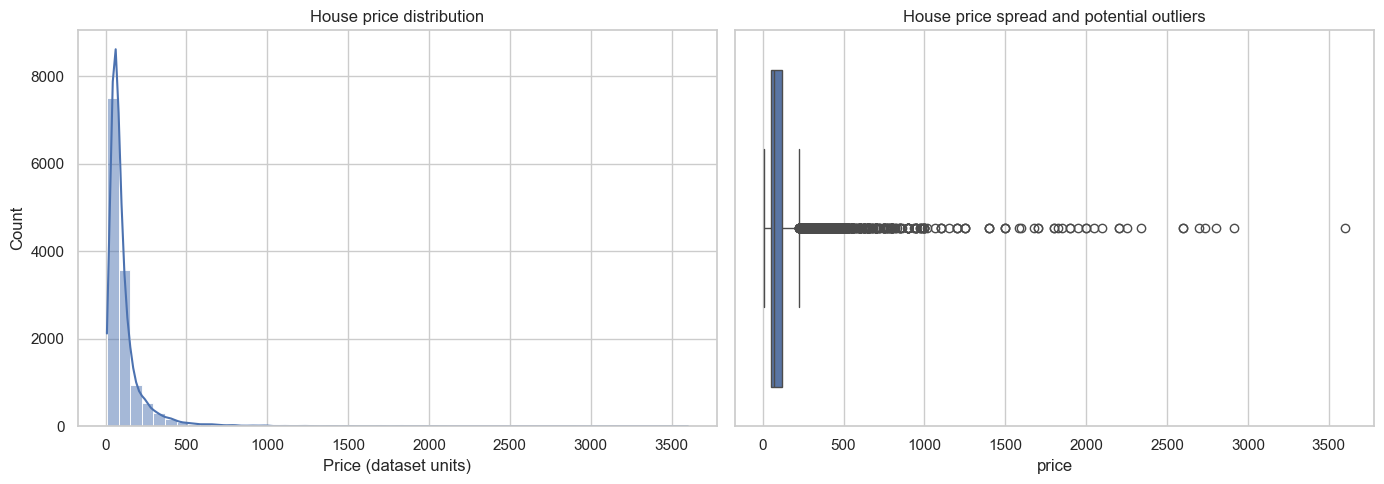

In [11]:
if "price" not in df.columns:
    raise KeyError("Expected target column 'price' was not found. Inspect df.columns.")

display(df["price"].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df, x="price", bins=50, kde=True, ax=axes[0])
axes[0].set_title("House price distribution")
axes[0].set_xlabel("Price (dataset units)")
sns.boxplot(data=df, x="price", ax=axes[1])
axes[1].set_title("House price spread and potential outliers")
plt.tight_layout()
plt.show()

## 4. Numeric feature relationships
Review numeric distributions and correlations. Correlation is not causation.

,count,mean,std,min,25%,50%,75%,max
bath,13247.0,2.692610,1.341458,1.0,2.0,2.0,3.0,40.0
balcony,12711.0,1.584376,0.817263,0.0,1.0,2.0,2.0,3.0
price,13320.0,112.565627,148.971674,8.0,50.0,72.0,120.0,3600.0


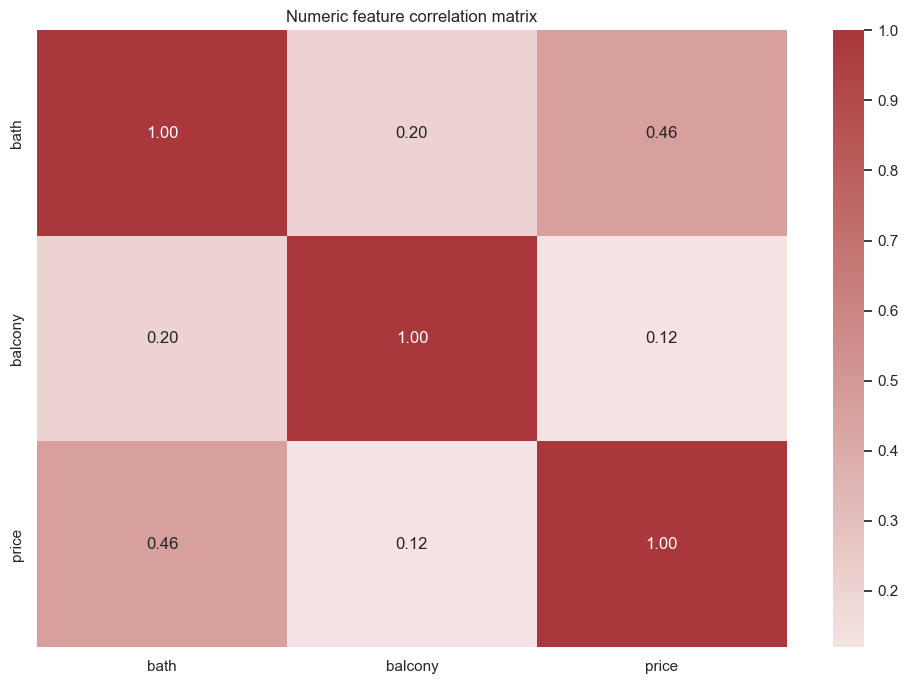

In [12]:
numeric_df = df.select_dtypes(include=np.number)
display(numeric_df.describe().T)

if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(numeric_df.corr(), annot=True, cmap="vlag", center=0, fmt=".2f")
    plt.title("Numeric feature correlation matrix")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a correlation matrix.")

## 5. Categorical feature cardinality
High-cardinality columns such as location need deliberate encoding strategies.

In [13]:
categorical_columns = df.select_dtypes(include=["object", "category"]).columns
cardinality = pd.DataFrame({
    "unique_values": df[categorical_columns].nunique(dropna=True),
    "missing_values": df[categorical_columns].isna().sum(),
})
display(cardinality.sort_values("unique_values", ascending=False))

if "location" in df.columns:
    display(df["location"].value_counts(dropna=False).head(20).to_frame("count"))

,unique_values,missing_values
society,2688,5502
total_sqft,2117,0
location,1305,1
availability,81,0
size,31,16
area_type,4,0


,count
location,
Whitefield,540
Sarjapur Road,399
Electronic City,302
Kanakpura Road,273
Thanisandra,234
Yelahanka,213
Uttarahalli,186
Hebbal,177
Marathahalli,175


In [14]:
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (
        df.isna().mean() * 100
    ).round(2)
})

display(missing_report.sort_values(
    "missing_percentage",
    ascending=False
))

print("Duplicate rows:", df.duplicated().sum())

,missing_count,missing_percentage
society,5502,41.31
balcony,609,4.57
bath,73,0.55
size,16,0.12
location,1,0.01
area_type,0,0.00
availability,0,0.00
total_sqft,0,0.00
price,0,0.00


Duplicate rows: 529


In [15]:
print(df["price"].describe())

print("\nSkewness:", df["price"].skew())

count    13320.000000
mean       112.565627
std        148.971674
min          8.000000
25%         50.000000
50%         72.000000
75%        120.000000
max       3600.000000
Name: price, dtype: float64

Skewness: 8.064468821273252


## 6. Initial findings
After running the notebook, record evidence-based observations here:
- Which columns have the most missing data?
- Are there duplicate rows?
- Is the price distribution skewed?
- Which columns are numeric versus categorical?
- Which columns may contain inconsistent formats?

**Do not clean the dataset in this notebook.** We will use these findings to design a separate, reproducible preprocessing pipeline.